# **Importing Libraries**

In [64]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

# **Flight Price Prediction (Regression)**

**Goal:** predict the ticket `price` of a domestic flight from its airline, route, timing, stops, duration, class and days left before departure.

**How this notebook is organised** (same flow as a classic EDA → preprocessing → modelling project):

1. Exploratory Data Analysis: look at the data, then Univariate → Bivariate → Multivariate analysis
2. Missing / bad data diagnosis
3. String data preprocessing (convert text columns to numbers)
4. Machine learning: split → train → evaluate → tune
5. Conclusion, Kaggle submission, saving the model

Because `price` is a **number**, this is a **regression** problem. So instead of accuracy / confusion matrix (used for classification) we evaluate with **MAE, RMSE and R²**.

# **Exploratory Data Analysis**

First we look at the raw data: its size, columns, types and basic statistics.

In [65]:
df = pd.read_csv('data/train.csv')
df.head()

,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,2856,Southwest,WN 3596,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,21812,Southwest,WN 1307,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,476,United,UA 1763,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129
3,21802,Southwest,WN 367,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94
4,5099,United,UA 2117,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146


In [66]:
df.shape

(18076, 12)

In [67]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18076 entries, 0 to 18075
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                18076 non-null  int64  
 1   airline           18076 non-null  object 
 2   flight            18076 non-null  object 
 3   source_city       18076 non-null  object 
 4   departure_time    18076 non-null  object 
 5   stops             18076 non-null  object 
 6   arrival_time      18076 non-null  object 
 7   destination_city  18076 non-null  object 
 8   flight_class      18076 non-null  object 
 9   duration          18076 non-null  float64
 10  days_left         18076 non-null  int64  
 11  price             18076 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 1.7+ MB


In [68]:
df.sample(5)

,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
737,12079,Alaska_Airlines,AS 2467,San Jose,Morning,one,Evening,Los Angeles,Economy,5.00,21,386
3030,13643,Southwest,WN 200,Los Angeles,Morning,zero,Morning,Sacramento,Economy,1.42,24,121
13765,20596,Southwest,WN 2514,Los Angeles,Morning,zero,Morning,Sacramento,Economy,1.42,39,131
3084,15970,Southwest,WN 685,Los Angeles,Evening,one,Night,San Diego,Economy,4.00,27,219
4681,17114,Alaska_Airlines,AS 3410,Sacramento,Evening,zero,Night,San Diego,Economy,1.85,33,79


In [69]:
df.describe(include = 'all')

,id,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
count,18076.000000,18076,18076,18076,18076,18076,18076,18076,18076,18076.000000,18076.000000,18076.000000
unique,NaN,7,1123,5,6,3,6,5,2,NaN,NaN,NaN
top,NaN,Alaska_Airlines,AA 6279,Los Angeles,Morning,zero,Afternoon,Los Angeles,Economy,NaN,NaN,NaN
freq,NaN,4554,183,4561,5144,13559,4785,4533,10711,NaN,NaN,NaN
mean,11308.626189,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.746853,20.520912,280.264550
std,6526.337957,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.947519,12.094984,221.965133
min,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.870000,1.000000,0.000000
25%,5668.750000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.470000,10.000000,157.000000
50%,11329.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.630000,20.000000,234.000000
75%,16949.500000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.000000,31.000000,336.000000


**What we get from this df.info():** 
There are 18076 rows/entries and 12 columns/attributes

**What each column means**

| Column | Meaning | Type |
|---|---|---|
| `id` | row identifier; carries no information about price | identifier |
| `airline` | airline name | categorical |
| `flight` | flight code, e.g. `WN 3596` | categorical (1000+ values) |
| `source_city`, `destination_city` | where the flight starts / ends | categorical |
| `departure_time`, `arrival_time` | time-of-day bucket | categorical |
| `stops` | number of stops | categorical (ordered) |
| `flight_class` | Economy / Business | categorical |
| `duration` | flight duration in hours | numeric |
| `days_left` | days between booking and departure | numeric |
| **`price`** | **target: what we want to predict** | numeric |

In [70]:
df.isnull().sum()

id                  0
airline             0
flight              0
source_city         0
departure_time      0
stops               0
arrival_time        0
destination_city    0
flight_class        0
duration            0
days_left           0
price               0
dtype: int64

**Observation:** there are no missing values in any column, so no imputation is needed. (We still do a missing-data check later, to be safe.)

In [71]:
df['flight_class'].value_counts()

Economy     10711
Business     7365
Name: flight_class, dtype: int64

In [72]:
df['stops'].value_counts()

zero           13559
one             4324
two_or_more      193
Name: stops, dtype: int64

In [73]:
df['id'].nunique(), df['flight'].nunique()

(18076, 1123)

`id` is just a row label (every value unique) and `flight` has over a thousand different codes. Neither is useful for a model directly, so they will go into `drop_cols`.

Now we group the columns by type. We will use these lists again and again.

In [74]:
target_cols = 'price'
cat_cols = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time', 'stops', 'flight_class']
num_cols = ['duration', 'days_left']
drop_cols = ['id', 'flight']

# **Univariate Analysis**

Univariate = looking at **one column at a time**. First the target, `price`.

A regression model behaves best when the target is roughly symmetric, so we check its shape, both raw and after a log transform.

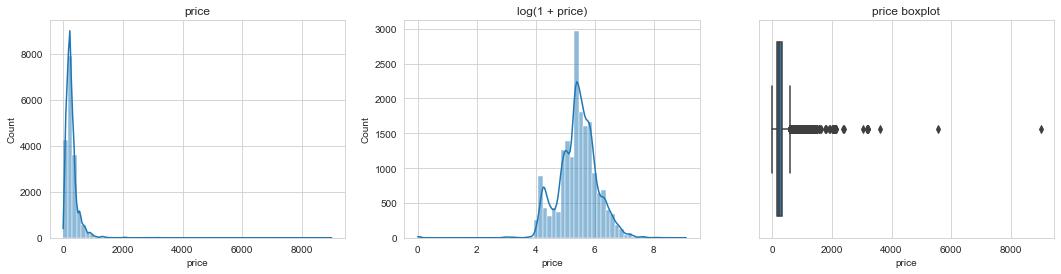

Skewness of price      : 7.07
Skewness of log(price) : -0.74
Rows with price == 0   : 25


In [75]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(df['price'], bins=60, kde=True, ax=ax[0]);  ax[0].set_title('price')
sns.histplot(np.log1p(df['price']), bins=60, kde=True, ax=ax[1]);  ax[1].set_title('log(1 + price)')
sns.boxplot(x=df['price'], ax=ax[2]);  ax[2].set_title('price boxplot')
plt.show()

print('Skewness of price      :', round(df['price'].skew(), 2))
print('Skewness of log(price) :', round(np.log1p(df['price']).skew(), 2))
print('Rows with price == 0   :', (df['price'] == 0).sum())

**Observation:** `price` has a long right tail (skewness about 7): most tickets are cheap and a few are very expensive. After `log(1 + price)` it is much more symmetric. We will test later whether training on the log price helps. We also see some `price = 0` rows, and a ticket can't be free, so these are probably errors that we'll deal with in the missing-data section.

Now each categorical column: how many rows per category?

airline
Alaska_Airlines             4554
American_Airlines           1797
Delta                       2972
Frontier                     799
Southern_Airways_Express       1
Southwest                   3895
United                      4058
Name: airline, dtype: int64


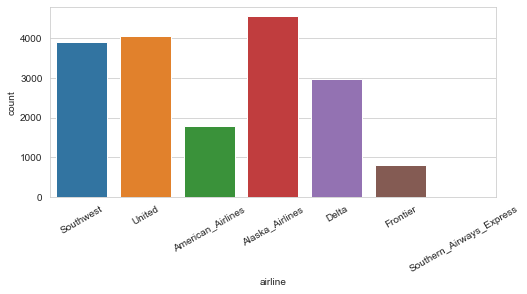

source_city
Los Angeles      4561
Sacramento       3521
San Diego        3691
San Francisco    4086
San Jose         2217
Name: source_city, dtype: int64


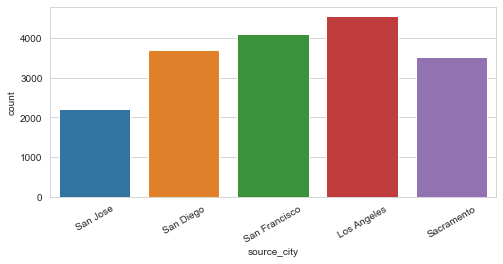

destination_city
Los Angeles      4533
Sacramento       3303
San Diego        3743
San Francisco    4073
San Jose         2424
Name: destination_city, dtype: int64


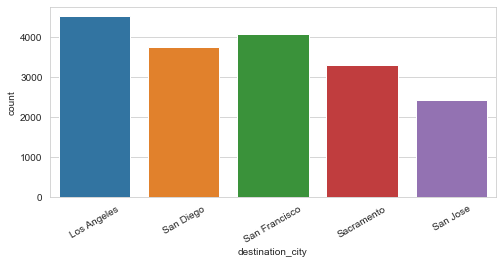

departure_time
Afternoon        3893
Early_Morning    2820
Evening          4436
Late_Night          6
Morning          5144
Night            1777
Name: departure_time, dtype: int64


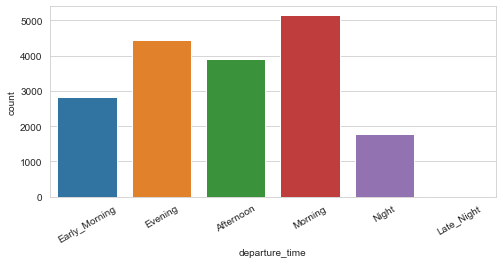

arrival_time
Afternoon        4785
Early_Morning     525
Evening          4549
Late_Night        152
Morning          4364
Night            3701
Name: arrival_time, dtype: int64


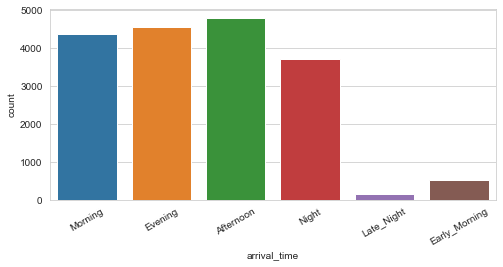

stops
one             4324
two_or_more      193
zero           13559
Name: stops, dtype: int64


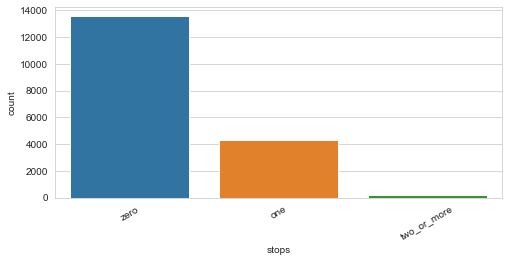

flight_class
Business     7365
Economy     10711
Name: flight_class, dtype: int64


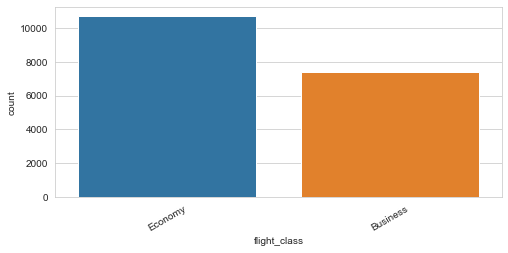

In [76]:
def cat_analyze(col) :
    print(col)
    print(df[col].value_counts().sort_index())
    plt.figure(figsize=(8, 3.5))
    sns.countplot(data = df, x = col)
    plt.xticks(rotation=30)
    plt.show()

for col in cat_cols :
    cat_analyze(col)

**Observations**
- `airline` has one airline (`Southern_Airways_Express`) with a single row, and `departure_time` has `Late_Night` with only 6 rows. A model can't learn anything reliable from 1 to 6 examples.
- `stops`: most flights are non-stop (`zero`); `two_or_more` is rare.
- The two classes are not balanced (more Economy than Business).

Now the numeric columns.

duration


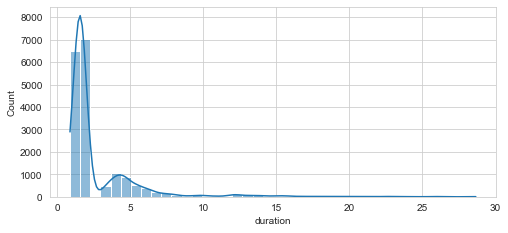

days_left


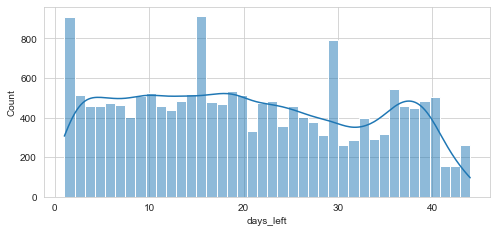

In [77]:
def num_analyze(col):
    print(col)
    plt.figure(figsize=(8, 3.5))
    sns.histplot(df[col], bins=40, kde=True)
    plt.show()

for col in num_cols:
    num_analyze(col)

**Observation:** `duration` is right-skewed too (most flights are short, a few last 20+ hours because of long layovers). `days_left` is spread fairly evenly between 1 and 44.

# **Bivariate Analysis**

Bivariate = **two columns together**. Here that means each feature against the target `price`. We want to find features whose categories sit at clearly different price levels, as those will be useful predictors.

airline
                          count   mean  median
airline                                       
Alaska_Airlines            4554  302.6   259.0
American_Airlines          1797  349.4   253.0
Delta                      2972  286.5   259.0
Frontier                    799  178.6   168.0
Southern_Airways_Express      1  543.0   543.0
Southwest                  3895  197.8   199.0
United                     4058  319.0   259.0


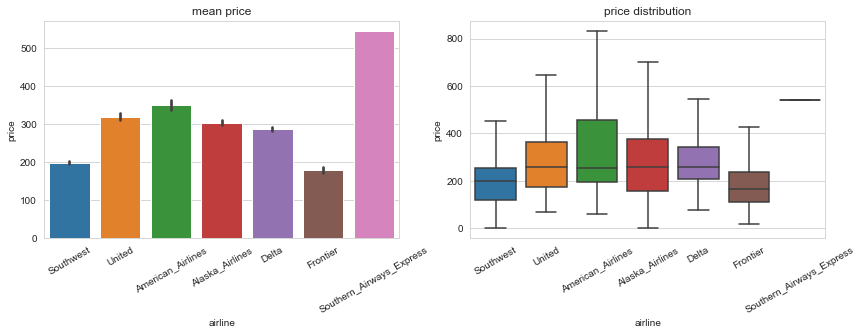

source_city
               count   mean  median
source_city                        
Los Angeles     4561  258.3   224.0
Sacramento      3521  353.5   279.0
San Diego       3691  234.1   220.0
San Francisco   4086  250.3   207.0
San Jose        2217  341.2   254.0


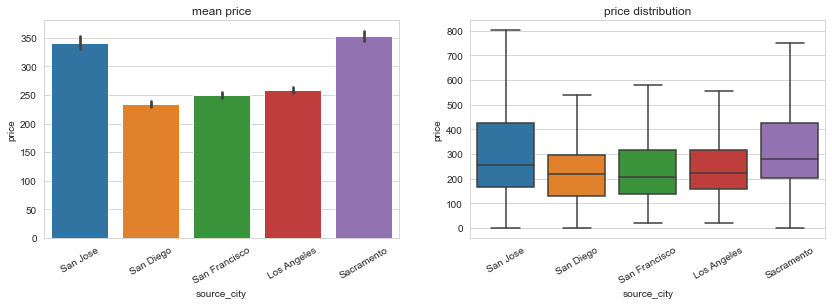

destination_city
                  count   mean  median
destination_city                      
Los Angeles        4533  258.7   224.0
Sacramento         3303  337.8   269.0
San Diego          3743  236.0   219.0
San Francisco      4073  249.7   215.0
San Jose           2424  362.0   264.0


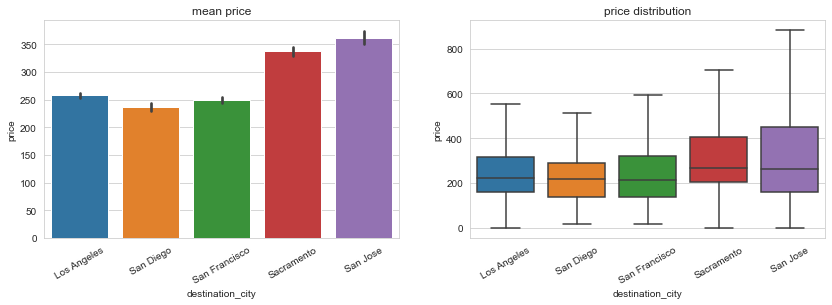

departure_time
                count    mean  median
departure_time                       
Afternoon        3893   285.0   234.0
Early_Morning    2820   294.5   234.0
Evening          4436   260.8   224.0
Late_Night          6  2743.3  1514.0
Morning          5144   298.0   234.0
Night            1777   236.4   217.0


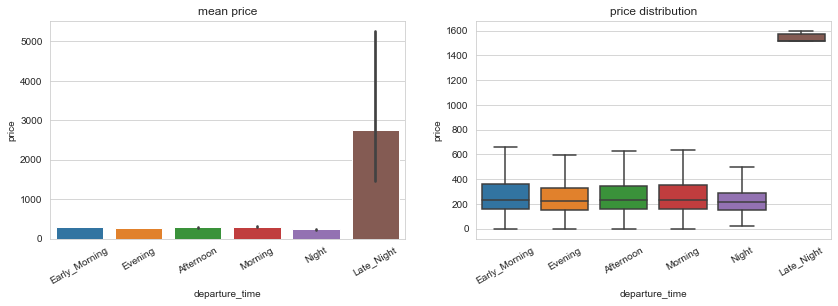

arrival_time
               count   mean  median
arrival_time                       
Afternoon       4785  301.9   242.0
Early_Morning    525  268.8   259.0
Evening         4549  295.5   234.0
Late_Night       152  209.4   199.0
Morning         4364  249.6   217.0
Night           3701  274.2   234.0


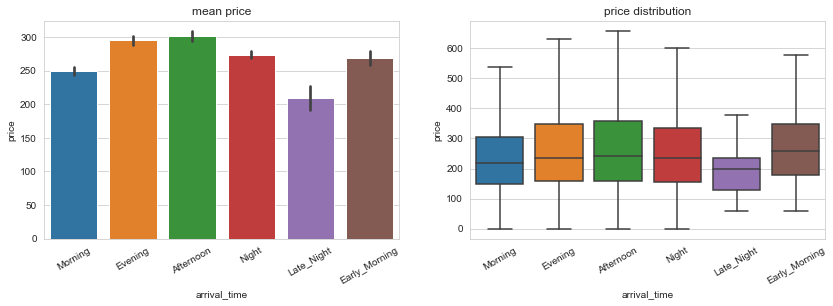

stops
             count   mean  median
stops                            
one           4324  431.5   347.0
two_or_more    193  425.7   370.0
zero         13559  230.0   214.0


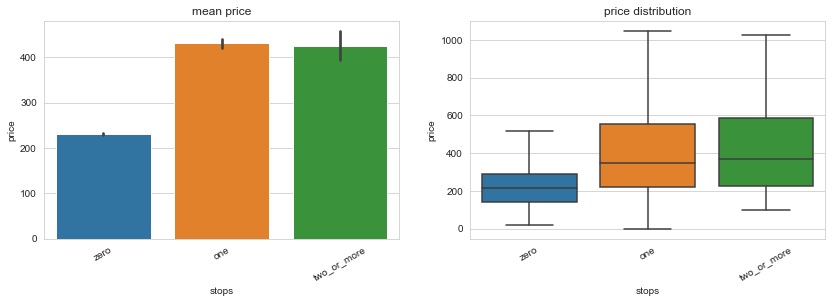

flight_class
              count   mean  median
flight_class                      
Business       7365  394.0   323.0
Economy       10711  202.1   194.0


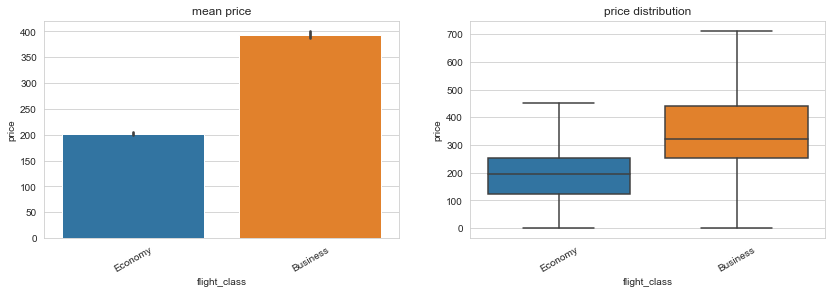

In [78]:
def cat_bivariate(col) :
    print(col)
    print(df.groupby(col)[target_cols].agg(['count', 'mean', 'median']).round(1))
    plt.figure(figsize=(14, 4))
    plt.subplot(1, 2, 1)
    sns.barplot(data=df, x=col, y=target_cols)
    plt.xticks(rotation=30)
    plt.title('mean price')
    plt.subplot(1, 2, 2)
    sns.boxplot(data=df, x=col, y=target_cols, showfliers=False)
    plt.xticks(rotation=30)
    plt.title('price distribution')
    plt.show()

for col in cat_cols:
    cat_bivariate(col)

**Observations**
- `flight_class`: Business tickets cost about twice as much as Economy. This looks like the strongest feature.
- `stops`: flights with a stop are clearly more expensive than non-stop ones.
- `airline`: Frontier and Southwest are cheaper than the others.
- Cities and times of day show smaller differences.

duration


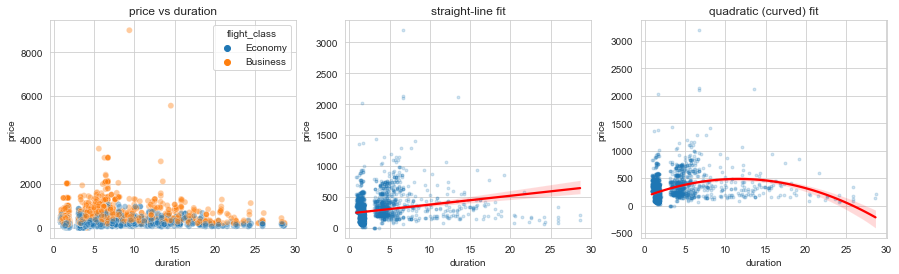

days_left


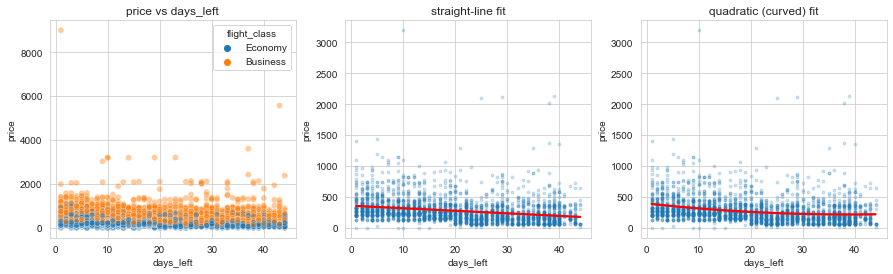

In [79]:
def num_bivariate(col) :
    print(col)
    plt.figure(figsize=(15,4))
    plt.subplot(1,3,1)
    sns.scatterplot(data=df, x=col, y=target_cols, hue='flight_class', alpha=0.4)
    plt.title(f'price vs {col}')
    plt.subplot(1,3,2)
    sns.regplot(data=df.sample(3000, random_state=101), x=col, y=target_cols, scatter_kws={'alpha':0.2, 's':8}, line_kws={'color':'red'})
    plt.title('straight-line fit')
    plt.subplot(1,3,3)
    sns.regplot(data=df.sample(3000, random_state=101), x=col, y=target_cols, order=2, scatter_kws={'alpha':0.2, 's':8}, line_kws={'color':'red'})
    plt.title('quadratic (curved) fit')
    plt.show()

for col in num_cols:
    num_bivariate(col)

**How to read this:** the middle plot fits a straight line, the right plot fits a curve (degree 2). If the curve follows the data noticeably better, that's a hint that **quadratic regression** may help. Notice also that Economy and Business form two separate clouds, so the relationship between price and `days_left` probably differs by class.

Correlation between the numeric columns:

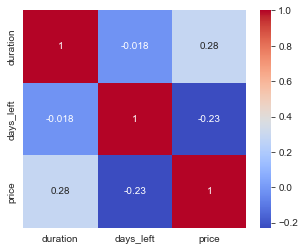

In [80]:
plt.figure(figsize=(5, 4))
sns.heatmap(df[num_cols + [target_cols]].corr(), annot=True, cmap='coolwarm')
plt.show()

In [81]:
print(df.groupby('flight_class')[num_cols + [target_cols]].corr().round(2))

                        duration  days_left  price
flight_class                                      
Business     duration       1.00      -0.01   0.31
             days_left     -0.01       1.00  -0.17
             price          0.31      -0.17   1.00
Economy      duration       1.00      -0.03   0.28
             days_left     -0.03       1.00  -0.46
             price          0.28      -0.46   1.00


**Observation:** overall correlations look weak, but when we split by class, `days_left` is clearly negatively correlated with price in Economy. So class acts as a hidden variable that changes the pattern.

# **Multivariate Analysis**

Multivariate = **three or more columns together**. Since `flight_class` seems so important, we repeat the price-by-category plots split (`hue`) by class.

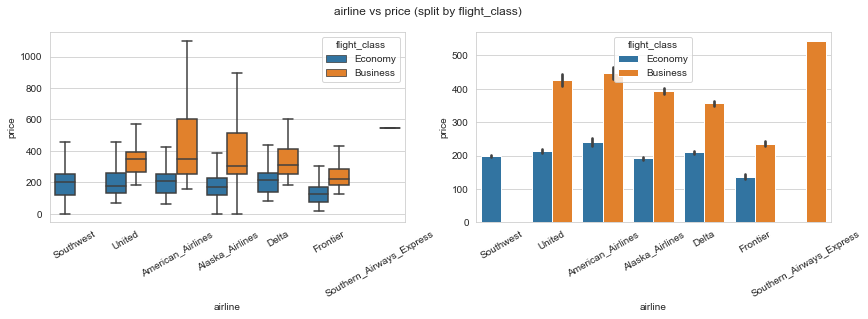

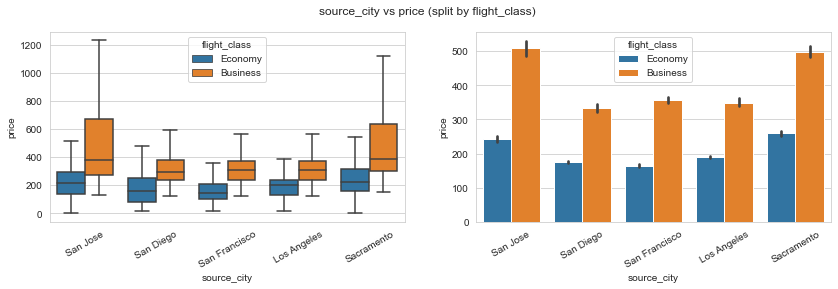

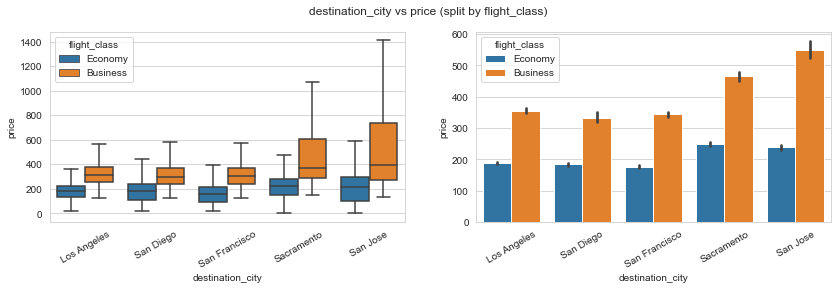

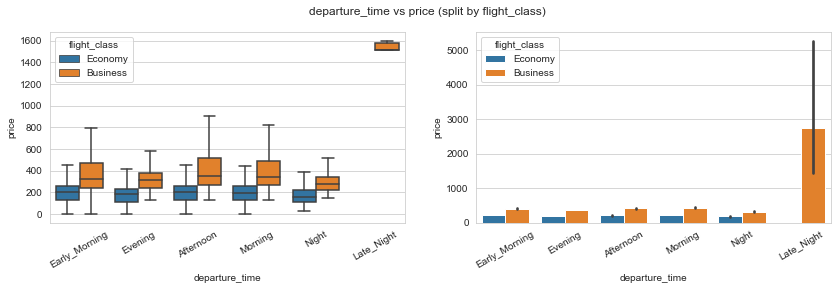

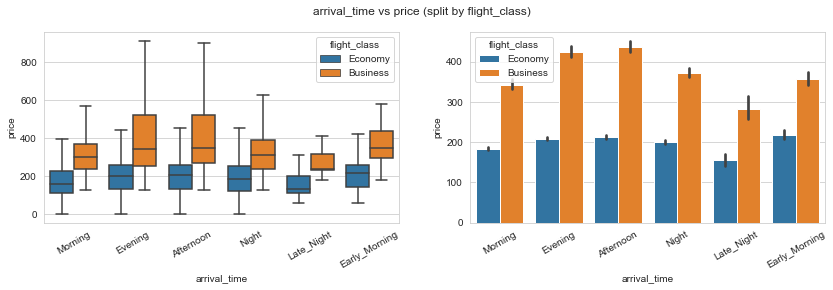

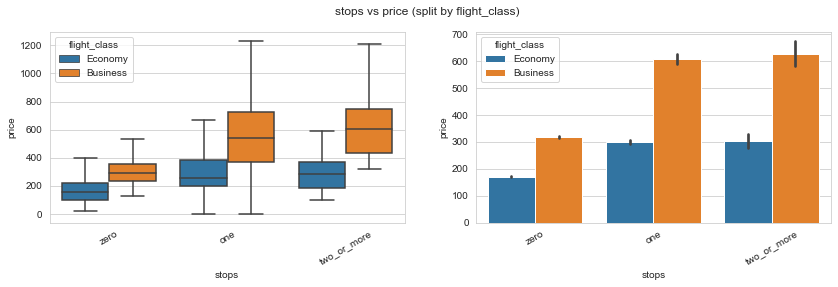

In [82]:
for col in cat_cols:
    if col == 'flight_class':
        continue
    plt.figure(figsize=(14, 3.5))
    plt.suptitle(f'{col} vs price (split by flight_class)')
    plt.subplot(1, 2, 1)
    sns.boxplot(data=df, x=col, y=target_cols, hue='flight_class', showfliers=False)
    plt.xticks(rotation=30)
    plt.subplot(1, 2, 2)
    sns.barplot(data=df, x=col, y=target_cols, hue='flight_class')
    plt.xticks(rotation=30)
    plt.show()

**Observation:** the price pattern across airlines, stops etc. is repeated at two different levels (Economy, Business), so the effects of class and other features **multiply**, rather than just add up. That's an *interaction*, which plain multiple regression cannot capture but polynomial terms and trees can.

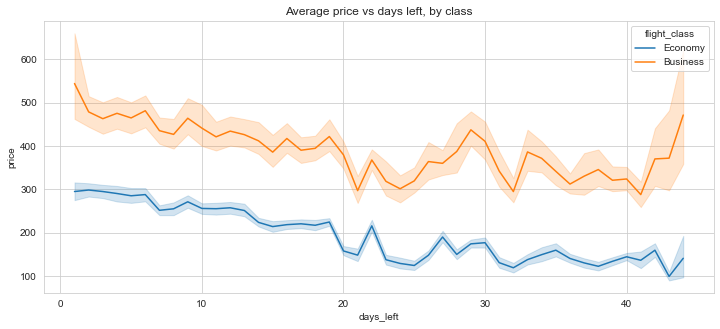

In [83]:
plt.figure(figsize=(12, 5))
sns.lineplot(data=df, x='days_left', y=target_cols, hue='flight_class')
plt.title('Average price vs days left, by class')
plt.show()

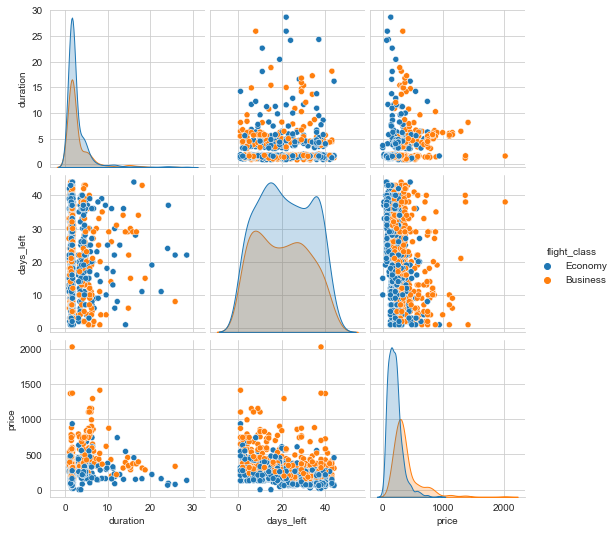

In [84]:
sns.pairplot(data = df[num_cols + [target_cols, 'flight_class']].sample(1000, random_state=101), hue='flight_class')
plt.show()

# **Missing / Bad Data Diagnosis**

In [85]:
100 * pd.isnull(df).sum()/len(df)

id                  0.0
airline             0.0
flight              0.0
source_city         0.0
departure_time      0.0
stops               0.0
arrival_time        0.0
destination_city    0.0
flight_class        0.0
duration            0.0
days_left           0.0
price               0.0
dtype: float64

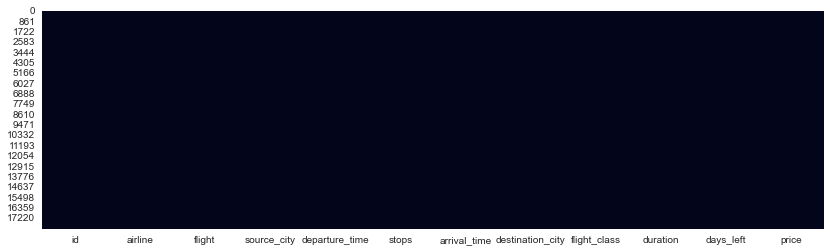

In [86]:
fig = plt.figure(figsize=(14, 4))
sns.heatmap(pd.isnull(df), cbar=False)
plt.show()

No missing values at all (the heatmap is a single solid colour). But missing values are not the only data problem; we also check for **duplicates**, **impossible values** and **ultra-rare categories**.

In [87]:
feature_cols_all = [c for c in df.columns if c != 'id']
print('Duplicate rows (ignoring id):', df.duplicated(subset=feature_cols_all).sum())
print('Rows with price == 0       :', (df['price'] == 0).sum())
print('Rows with price < 20       :', (df['price'] < 20).sum())

Duplicate rows (ignoring id): 6
Rows with price == 0       : 25
Rows with price < 20       : 42


In [88]:
MIN_COUNT = 30
rare_levels = {}
for col in cat_cols:
    vc = df[col].value_counts()
    rare_levels[col] = vc[vc < MIN_COUNT].index.tolist()
print({k: v for k, v in rare_levels.items() if v})

{'airline': ['Southern_Airways_Express'], 'departure_time': ['Late_Night']}


**Decisions**
1. **Drop duplicate rows** (the same row in training and test part would make scores look better than reality).
2. **Drop `price == 0` rows** (data errors that distort the error metric).
3. **Drop rows with ultra-rare categories** (< 30 rows). The few rows are not enough to learn from, and flexible models (e.g. quadratic with interactions) extrapolate wildly on them.

In [89]:
print('Before:', df.shape)
df = df.drop_duplicates(subset=feature_cols_all)
df = df[df['price'] > 0]
for col, levels in rare_levels.items():
    df = df[~df[col].isin(levels)]
df = df.reset_index(drop=True)
print('After :', df.shape)

Before: (18076, 12)
After : (18038, 12)


In [90]:
df.drop(drop_cols, axis=1, inplace=True)
df.head(2)

,airline,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,Southwest,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,Southwest,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149


In [91]:
df.shape
df.head(5)

,airline,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,Southwest,San Jose,Early_Morning,zero,Morning,Los Angeles,Economy,1.33,5,315
1,Southwest,San Jose,Evening,zero,Evening,San Diego,Economy,1.58,40,149
2,United,San Diego,Afternoon,zero,Afternoon,San Francisco,Economy,1.77,2,129
3,Southwest,San Jose,Morning,zero,Morning,San Diego,Economy,1.58,40,94
4,United,San Diego,Afternoon,zero,Evening,San Francisco,Economy,1.70,9,146


# **String Data Preprocessing / Creating Dummies for string**

Models can only use numbers, so each text column must be converted.

| Column type | Method | Why |
|---|---|---|
| Two values (`flight_class`) | map to 0 / 1 | simplest |
| Ordered categories (`stops`) | map to 0 / 1 / 2 | order is meaningful (more stops = more) |
| Unordered categories (airline, cities, times) | **dummies** (one-hot) | avoids inventing a false order |

In [92]:
# flight_class: binary map
def binary_map(x):
    return x.map({'Economy': 0, 'Business': 1})

df[['flight_class']] = df[['flight_class']].apply(binary_map)
df.head()

,airline,source_city,departure_time,stops,arrival_time,destination_city,flight_class,duration,days_left,price
0,Southwest,San Jose,Early_Morning,zero,Morning,Los Angeles,0,1.33,5,315
1,Southwest,San Jose,Evening,zero,Evening,San Diego,0,1.58,40,149
2,United,San Diego,Afternoon,zero,Afternoon,San Francisco,0,1.77,2,129
3,Southwest,San Jose,Morning,zero,Morning,San Diego,0,1.58,40,94
4,United,San Diego,Afternoon,zero,Evening,San Francisco,0,1.70,9,146


In [93]:
# stops: ordered map
df['stops'] = df['stops'].map({'zero': 0, 'one': 1, 'two_or_more': 2})
df['stops'].value_counts()

0    13559
1     4293
2      186
Name: stops, dtype: int64

In [94]:
# the rest: dummies. drop_first=True removes one redundant column per variable
dummy_cols = ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time']
df = pd.get_dummies(df, columns=dummy_cols, drop_first=True, dtype=int)
df.head()

,stops,flight_class,duration,days_left,price,airline_American_Airlines,airline_Delta,airline_Frontier,airline_Southwest,airline_United,...,destination_city_San Jose,departure_time_Early_Morning,departure_time_Evening,departure_time_Morning,departure_time_Night,arrival_time_Early_Morning,arrival_time_Evening,arrival_time_Late_Night,arrival_time_Morning,arrival_time_Night
0,0,0,1.33,5,315,0,0,0,1,0,...,0,1,0,0,0,0,0,0,1,0
1,0,0,1.58,40,149,0,0,0,1,0,...,0,0,1,0,0,0,1,0,0,0
2,0,0,1.77,2,129,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,0,0,1.58,40,94,0,0,0,1,0,...,0,0,0,1,0,0,0,0,1,0
4,0,0,1.70,9,146,0,0,0,0,1,...,0,0,0,0,0,0,1,0,0,0


In [95]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18038 entries, 0 to 18037
Data columns (total 27 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   stops                           18038 non-null  int64  
 1   flight_class                    18038 non-null  int64  
 2   duration                        18038 non-null  float64
 3   days_left                       18038 non-null  int64  
 4   price                           18038 non-null  int64  
 5   airline_American_Airlines       18038 non-null  int32  
 6   airline_Delta                   18038 non-null  int32  
 7   airline_Frontier                18038 non-null  int32  
 8   airline_Southwest               18038 non-null  int32  
 9   airline_United                  18038 non-null  int32  
 10  source_city_Sacramento          18038 non-null  int32  
 11  source_city_San Diego           18038 non-null  int32  
 12  source_city_San Francisco       

In [96]:
df.columns

Index(['stops', 'flight_class', 'duration', 'days_left', 'price',
       'airline_American_Airlines', 'airline_Delta', 'airline_Frontier',
       'airline_Southwest', 'airline_United', 'source_city_Sacramento',
       'source_city_San Diego', 'source_city_San Francisco',
       'source_city_San Jose', 'destination_city_Sacramento',
       'destination_city_San Diego', 'destination_city_San Francisco',
       'destination_city_San Jose', 'departure_time_Early_Morning',
       'departure_time_Evening', 'departure_time_Morning',
       'departure_time_Night', 'arrival_time_Early_Morning',
       'arrival_time_Evening', 'arrival_time_Late_Night',
       'arrival_time_Morning', 'arrival_time_Night'],
      dtype='object')

Now that everything is numeric we can look at the correlation of every column with `price`:

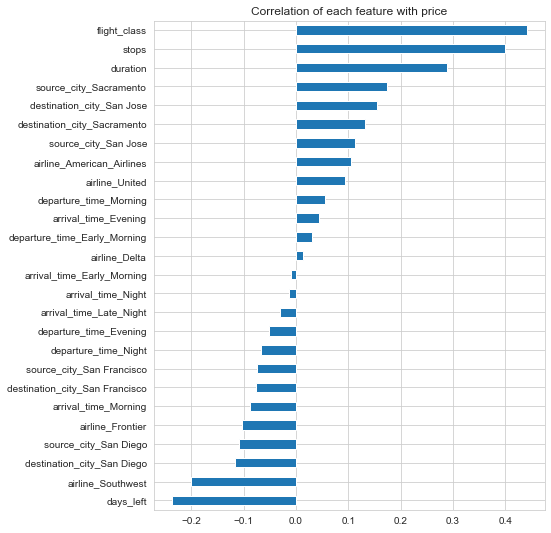

In [97]:
corr_price = df.corr()[target_cols].drop(target_cols).sort_values()
plt.figure(figsize=(7, 9))
corr_price.plot.barh()
plt.title('Correlation of each feature with price')
plt.show()

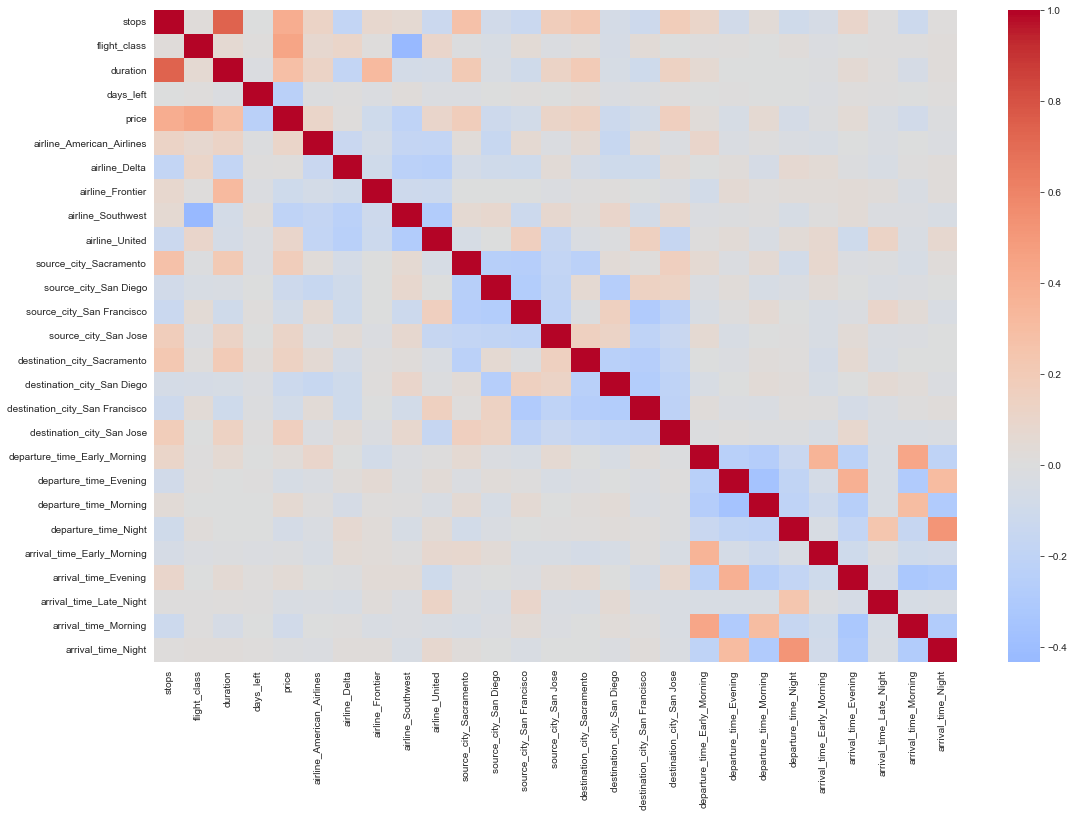

In [98]:
fig = plt.figure(figsize=(18, 12))
sns.heatmap(df.corr(), cmap='coolwarm', center=0)
plt.show()

**Observation:** `flight_class` and `stops` have the largest correlation with price, in line with the EDA. Next we separate the target from the features.

In [99]:
target = df[target_cols]
features = df.drop(target_cols, axis = 1)
print(features.shape, target.shape)

(18038, 26) (18038,)


In [100]:
features.head()

,stops,flight_class,duration,days_left,airline_American_Airlines,airline_Delta,airline_Frontier,airline_Southwest,airline_United,source_city_Sacramento,...,destination_city_San Jose,departure_time_Early_Morning,departure_time_Evening,departure_time_Morning,departure_time_Night,arrival_time_Early_Morning,arrival_time_Evening,arrival_time_Late_Night,arrival_time_Morning,arrival_time_Night
0,0,0,1.33,5,0,0,0,1,0,0,...,0,1,0,0,0,0,0,0,1,0
1,0,0,1.58,40,0,0,0,1,0,0,...,0,0,1,0,0,0,1,0,0,0
2,0,0,1.77,2,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,1.58,40,0,0,0,1,0,0,...,0,0,0,1,0,0,0,0,1,0
4,0,0,1.70,9,0,0,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0


# **Machine Learning Template**

## **Data Splitting**
We hold back 25% of the data as a **test set** that the model never sees during training. Training scores tell us how well a model memorised; the test scores tell us how well it **generalises**, which is what matters on Kaggle's private test data.

In [101]:
from sklearn.model_selection import train_test_split
xtrain, xtest, ytrain, ytest = train_test_split(features, target, test_size=0.25, random_state=101)
print(xtrain.shape, xtest.shape)

(13528, 26) (4510, 26)


## **Evaluation helper**
Regression metrics (instead of accuracy / confusion matrix):
- **MAE**: average absolute error in dollars (lower = better)
- **RMSE**: like MAE but punishes big mistakes more (lower = better)
- **R²**: share of price variation explained (1 = perfect, 0 = same as always predicting the mean)

The function below trains a model, scores it on both train and test, and **records the result** in a table. That table goes straight into your report ("model name, best score, observation").

`log=True` trains on `log(1 + price)` and converts predictions back to dollars automatically.

In [102]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import TransformedTargetRegressor

results = []
fitted = {}   # remembers every trained model by name

def evaluate(name, model, Xtr=None, Xte=None, log=False, notes=''):
    Xtr = xtrain if Xtr is None else Xtr
    Xte = xtest  if Xte is None else Xte
    if log:
        model = TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)
    model.fit(Xtr, ytrain)
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    row = {'model': name,
           'test_RMSE': np.sqrt(mean_squared_error(ytest, p_te)),
           'test_MAE': mean_absolute_error(ytest, p_te),
           'test_R2': r2_score(ytest, p_te),
           'train_RMSE': np.sqrt(mean_squared_error(ytrain, p_tr)),
           'notes': notes}
    results.append(row)
    fitted[name] = model
    print(f"{name:50s} test RMSE={row['test_RMSE']:7.2f} MAE={row['test_MAE']:7.2f} R2={row['test_R2']:.3f} | train RMSE={row['train_RMSE']:7.2f}")
    return model

**Train vs test RMSE is the over-fitting detector:** if train RMSE is much lower than test RMSE, the model memorised the training data (over-fitting). If both are high, it's too simple (under-fitting).

# **Model Creation & Training**

We go from simple to complex, so each step shows what extra flexibility buys us.

## **0. Baseline: always predict the average price**
Any real model must beat this.

In [103]:
from sklearn.dummy import DummyRegressor
m0 = evaluate('0. Baseline (predict mean)', DummyRegressor(strategy='mean'), notes='reference point')

0. Baseline (predict mean)                         test RMSE= 210.98 MAE= 133.54 R2=-0.000 | train RMSE= 211.28


## **1. Simple Linear Regression** (one feature): `price = w0 + w1 * x`
We try the three most promising single features separately.

In [104]:
from sklearn.linear_model import LinearRegression

for col in ['flight_class', 'stops', 'duration', 'days_left']:
    evaluate(f'1. Simple LR using only {col}', LinearRegression(), Xtr=xtrain[[col]], Xte=xtest[[col]], notes='one feature')

1. Simple LR using only flight_class               test RMSE= 190.40 MAE= 116.40 R2=0.185 | train RMSE= 189.24
1. Simple LR using only stops                      test RMSE= 194.77 MAE= 122.42 R2=0.148 | train RMSE= 193.15
1. Simple LR using only duration                   test RMSE= 203.36 MAE= 128.42 R2=0.071 | train RMSE= 201.86
1. Simple LR using only days_left                  test RMSE= 205.23 MAE= 127.23 R2=0.054 | train RMSE= 205.12


**Observation:** one feature explains only a small part of the price variation. `flight_class` is the best single feature. Using all features together should be better.

## **2. Multiple Linear Regression** (all features): `price = w0 + w1*x1 + w2*x2 + ...`
Weights are found by least squares. (Under Gaussian noise, least squares is exactly the **maximum likelihood estimate**, the MLE connection from class.)

In [105]:
model_mlr = evaluate('2. Multiple Linear Regression', LinearRegression(), notes='all features')

2. Multiple Linear Regression                      test RMSE= 156.07 MAE=  85.62 R2=0.453 | train RMSE= 150.63


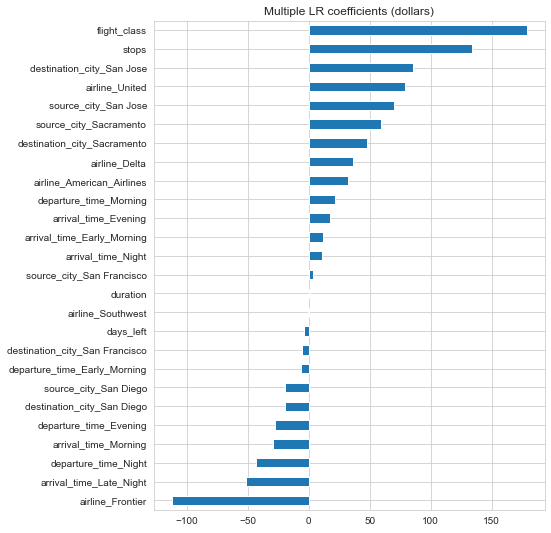

In [106]:
# Look at what the model learned: one weight per feature
coefs = pd.Series(model_mlr.coef_.ravel(), index=xtrain.columns).sort_values()
plt.figure(figsize=(7, 9)); coefs.plot.barh(); plt.title('Multiple LR coefficients (dollars)'); plt.show()

**Reading the plot:** a coefficient of +300 on `flight_class` means that, holding everything else fixed, Business costs about \$300 more than Economy. Dummy-variable coefficients are relative to the dropped (reference) category.

## **3. Multiple Linear Regression with log-transformed target**
The EDA showed `price` is skewed. We train on `log(1 + price)` and convert back.

In [107]:
model_mlr_log = evaluate('3. Multiple LR + log target', LinearRegression(), log=True, notes='log(1+price) target')

3. Multiple LR + log target                        test RMSE= 157.84 MAE=  79.58 R2=0.440 | train RMSE= 150.41


**Observation:** compare #2 and #3 on **both** RMSE and MAE. The log version often improves MAE (typical error) even when RMSE barely changes, because RMSE is dominated by the few very expensive tickets.

## **4. Quadratic Regression (numeric features)**
Add curved terms: `duration²`, `days_left²` and `duration × days_left`, so the model can bend.

In [108]:
def add_poly(data):
    d = data.copy()
    d['duration_sq']  = d['duration'] ** 2
    d['days_left_sq'] = d['days_left'] ** 2
    d['duration_x_days_left'] = d['duration'] * d['days_left']
    return d

xtrain_q, xtest_q = add_poly(xtrain), add_poly(xtest)
model_quad_num = evaluate('4. Quadratic (numeric features) + log', LinearRegression(), Xtr=xtrain_q, Xte=xtest_q, log=True, notes='squares + product of numeric columns')

4. Quadratic (numeric features) + log              test RMSE= 158.30 MAE=  80.01 R2=0.437 | train RMSE= 151.07


**Observation:** if this barely improves on #3, curvature in `duration` and `days_left` *alone* isn't what's missing. The next step adds interactions with the categorical features too.

## **5. Quadratic Regression (all features with interactions)**
`PolynomialFeatures(degree=2)` creates every square and every pair product of all columns (e.g. `flight_class × days_left`, `airline_Delta × stops`). This lets the effect of one feature **depend on another**. We scale first, because squares of unscaled numbers become huge.

In [109]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

quad_all = Pipeline([('poly', PolynomialFeatures(degree=2, include_bias=False)),
                     ('scale', StandardScaler()),
                     ('lr', LinearRegression())])
model_quad_all = evaluate('5. Quadratic (all features + interactions) + log', quad_all, log=True, notes='degree-2 polynomial on every feature')

5. Quadratic (all features + interactions) + log   test RMSE= 133.13 MAE=  58.64 R2=0.602 | train RMSE= 111.83


**Observation:** a big drop in error here means price depends on *combinations* of features. Compare train vs test RMSE to see whether it starts to over-fit.

## **Hyperparameter tuning: polynomial degree**
How curvy should the model be? We try degrees 1 to 5 on the two numeric columns (keeping the categorical features as they are) and plot train vs test error. This is the classic **bias–variance** picture: too simple = under-fit, too complex = over-fit.

degree 1: train RMSE=150.41  test RMSE=157.84
degree 2: train RMSE=151.07  test RMSE=158.30
degree 3: train RMSE=151.75  test RMSE=157.57
degree 4: train RMSE=152.73  test RMSE=157.97
degree 5: train RMSE=151.88  test RMSE=157.39
degree 6: train RMSE=148.47  test RMSE=155.38
degree 7: train RMSE=145.73  test RMSE=154.45


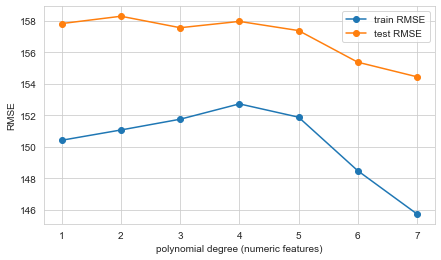

In [110]:
from sklearn.preprocessing import PolynomialFeatures

tr_err, te_err = [], []
degrees = range(1, 8)
for d in degrees:
    pf = PolynomialFeatures(degree=d, include_bias=False)
    ptr = pf.fit_transform(xtrain[num_cols]);  pte = pf.transform(xtest[num_cols])
    sc = StandardScaler().fit(ptr)
    Xtr_d = np.hstack([sc.transform(ptr), xtrain.drop(columns=num_cols).values])
    Xte_d = np.hstack([sc.transform(pte), xtest.drop(columns=num_cols).values])
    m = TransformedTargetRegressor(LinearRegression(), func=np.log1p, inverse_func=np.expm1).fit(Xtr_d, ytrain)
    tr_err.append(np.sqrt(mean_squared_error(ytrain, m.predict(Xtr_d))))
    te_err.append(np.sqrt(mean_squared_error(ytest,  m.predict(Xte_d))))
    print(f'degree {d}: train RMSE={tr_err[-1]:.2f}  test RMSE={te_err[-1]:.2f}')

plt.figure(figsize=(7, 4))
plt.plot(degrees, tr_err, 'o-', label='train RMSE'); plt.plot(degrees, te_err, 'o-', label='test RMSE')
plt.xlabel('polynomial degree (numeric features)'); plt.ylabel('RMSE'); plt.legend(); plt.show()

**Observation:** the test error barely changes across degrees (the differences are only a few dollars), so extra curvature in `duration` and `days_left` **alone** adds almost nothing. The missing signal is in *interactions with the categorical features*, which is exactly what model 5 (all-features quadratic) and the regression tree capture.

## **6. Regression Tree**
A regression tree asks a series of yes/no questions (*"is it Business class?"*, *"days_left < 15?"*) and predicts the **average price in the final group (leaf)**. It discovers interactions and non-linear effects automatically, and doesn't need scaling.

Key setting: **`max_depth`**. Shallow = under-fit, deep = over-fit. We scan many depths and plot train vs test error.

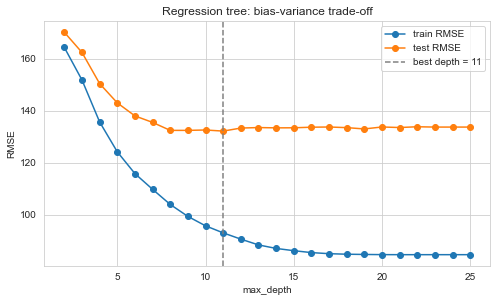

Best max_depth: 11


In [111]:
from sklearn.tree import DecisionTreeRegressor

depths = range(2, 26)
tr_err, te_err = [], []
for d in depths:
    t = DecisionTreeRegressor(max_depth=d, min_samples_leaf=5, random_state=101).fit(xtrain, ytrain)
    tr_err.append(np.sqrt(mean_squared_error(ytrain, t.predict(xtrain))))
    te_err.append(np.sqrt(mean_squared_error(ytest,  t.predict(xtest))))

best_depth = list(depths)[int(np.argmin(te_err))]
plt.figure(figsize=(8, 4.5))
plt.plot(depths, tr_err, 'o-', label='train RMSE'); plt.plot(depths, te_err, 'o-', label='test RMSE')
plt.axvline(best_depth, color='gray', ls='--', label=f'best depth = {best_depth}')
plt.xlabel('max_depth'); plt.ylabel('RMSE'); plt.legend(); plt.title('Regression tree: bias-variance trade-off'); plt.show()
print('Best max_depth:', best_depth)

In [112]:
model_tree     = evaluate(f'6a. Regression Tree (depth={best_depth})', DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=5, random_state=101), notes='tuned max_depth')
model_tree_log = evaluate(f'6b. Regression Tree (depth={best_depth}) + log', DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=5, random_state=101), log=True, notes='log target')

6a. Regression Tree (depth=11)                     test RMSE= 132.14 MAE=  50.15 R2=0.608 | train RMSE=  93.08
6b. Regression Tree (depth=11) + log               test RMSE= 131.77 MAE=  48.71 R2=0.610 | train RMSE=  96.32


`min_samples_leaf` is the minimum number of rows allowed in a leaf. A larger value gives smoother, less over-fitted trees.

In [113]:
for leaf in [1, 5, 10, 20, 50]:
    evaluate(f'6c. Tree depth={best_depth}, min_samples_leaf={leaf} + log',
             DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=leaf, random_state=101), log=True, notes='leaf-size experiment')

6c. Tree depth=11, min_samples_leaf=1 + log        test RMSE= 143.67 MAE=  50.28 R2=0.536 | train RMSE=  85.80
6c. Tree depth=11, min_samples_leaf=5 + log        test RMSE= 131.77 MAE=  48.71 R2=0.610 | train RMSE=  96.32
6c. Tree depth=11, min_samples_leaf=10 + log       test RMSE= 130.29 MAE=  49.36 R2=0.619 | train RMSE= 102.20
6c. Tree depth=11, min_samples_leaf=20 + log       test RMSE= 131.84 MAE=  51.70 R2=0.609 | train RMSE= 110.28
6c. Tree depth=11, min_samples_leaf=50 + log       test RMSE= 141.08 MAE=  56.93 R2=0.553 | train RMSE= 124.04


## **Feature Importance**
Which features does the tree rely on? Then we check whether a tree using only the important ones does as well (a simpler model is easier to explain).

In [114]:
imp = pd.DataFrame(model_tree.feature_importances_, index = xtrain.columns, columns=['Importance']).sort_values(by='Importance', ascending=False)
imp.head(10)

,Importance
duration,0.415946
flight_class,0.245403
days_left,0.125826
airline_United,0.063465
destination_city_San Jose,0.024642
airline_Frontier,0.023092
source_city_San Jose,0.017595
airline_Delta,0.014503
airline_American_Airlines,0.013122
source_city_Sacramento,0.012727


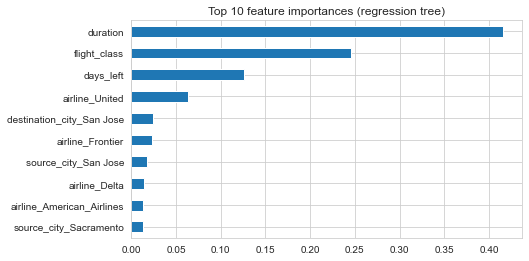

In [115]:
imp.head(10).iloc[::-1].plot.barh(figsize=(7, 4), legend=False); plt.title('Top 10 feature importances (regression tree)'); plt.show()

In [116]:
imp_cols = imp.index[:8].tolist()
print(imp_cols)
model_tree_imp = evaluate(f'6d. Tree on top-8 important features + log', DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=5, random_state=101),
                          Xtr=xtrain[imp_cols], Xte=xtest[imp_cols], log=True, notes='only 8 features')

['duration', 'flight_class', 'days_left', 'airline_United', 'destination_city_San Jose', 'airline_Frontier', 'source_city_San Jose', 'airline_Delta']
6d. Tree on top-8 important features + log         test RMSE= 134.04 MAE=  55.76 R2=0.596 | train RMSE= 101.23


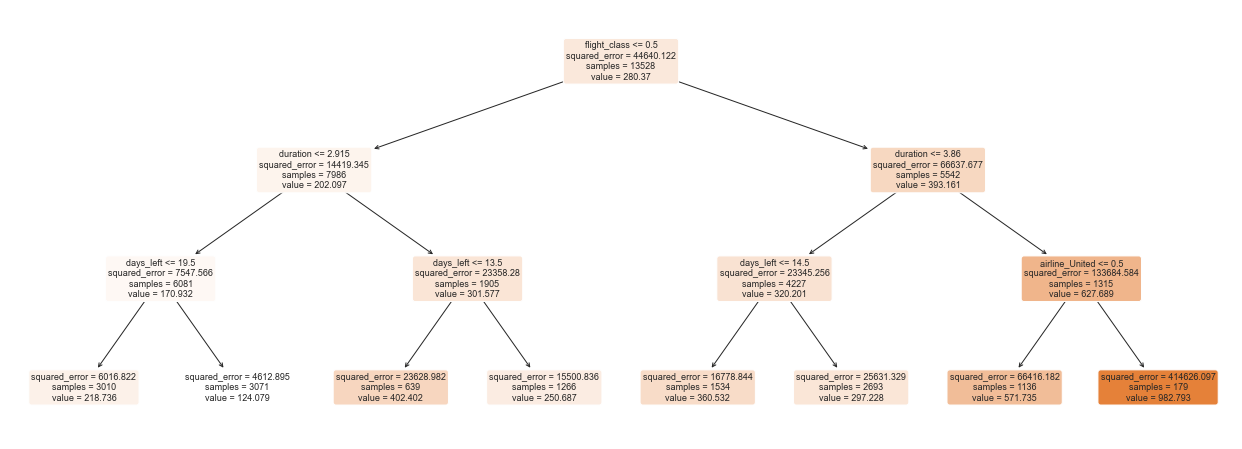

In [117]:
# A small tree (depth 3) drawn as a flowchart, easy to explain in a viva
from sklearn.tree import plot_tree
small = DecisionTreeRegressor(max_depth=3, random_state=101).fit(xtrain, ytrain)
plt.figure(figsize=(22, 8))
plot_tree(small, feature_names=list(xtrain.columns), filled=True, rounded=True, fontsize=9)
plt.show()

# **Model Evaluation**

## **Results table**
This is the consolidated "model vs best score" table the project report asks for.

In [118]:
res = pd.DataFrame(results).sort_values('test_RMSE').reset_index(drop=True)
res.round(3)

,model,test_RMSE,test_MAE,test_R2,train_RMSE,notes
0,"6c. Tree depth=11, min_samples_leaf=10 + log",130.292,49.360,0.619,102.204,leaf-size experiment
1,"6c. Tree depth=11, min_samples_leaf=5 + log",131.773,48.711,0.610,96.324,leaf-size experiment
2,6b. Regression Tree (depth=11) + log,131.773,48.711,0.610,96.324,log target
3,"6c. Tree depth=11, min_samples_leaf=20 + log",131.838,51.704,0.609,110.283,leaf-size experiment
4,6a. Regression Tree (depth=11),132.139,50.149,0.608,93.082,tuned max_depth
5,5. Quadratic (all features + interactions) + log,133.134,58.636,0.602,111.835,degree-2 polynomial on every feature
6,6d. Tree on top-8 important features + log,134.037,55.759,0.596,101.233,only 8 features
7,"6c. Tree depth=11, min_samples_leaf=50 + log",141.083,56.930,0.553,124.045,leaf-size experiment
8,"6c. Tree depth=11, min_samples_leaf=1 + log",143.671,50.277,0.536,85.804,leaf-size experiment
9,2. Multiple Linear Regression,156.072,85.617,0.453,150.633,all features


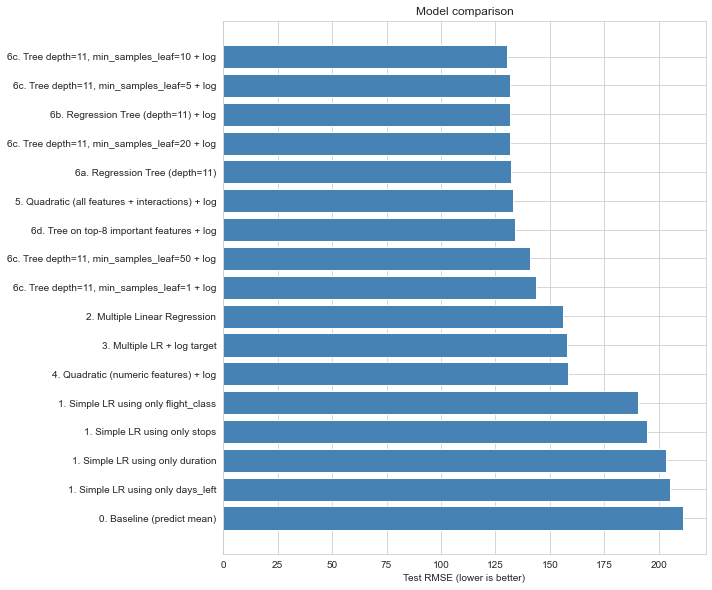

In [119]:
p = res.iloc[::-1]
plt.figure(figsize=(10, 0.4 * len(p) + 1.5))
plt.barh(p['model'], p['test_RMSE'], color='steelblue')
plt.xlabel('Test RMSE (lower is better)'); plt.title('Model comparison'); plt.tight_layout(); plt.show()

## **Residual analysis of the best model**
A *residual* is `actual − predicted`. Plots of residuals show where the model fails.

Best model on the test split: 6c. Tree depth=11, min_samples_leaf=10 + log


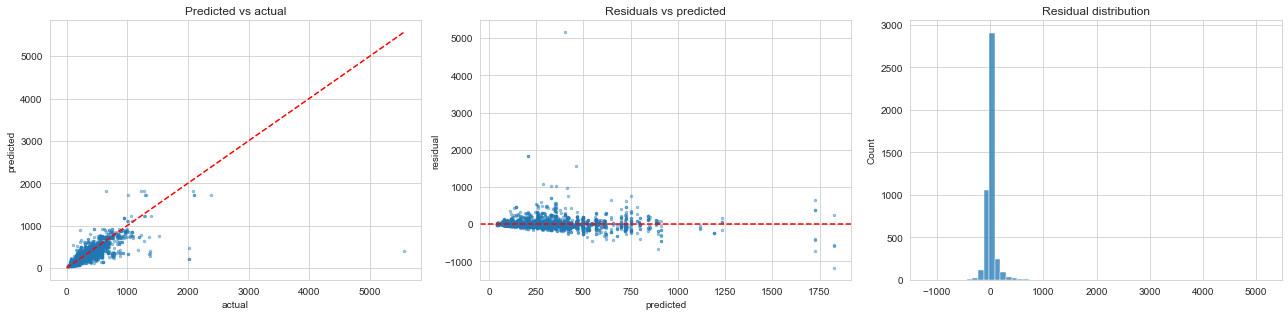

In [120]:
best_name = res.loc[0, 'model']
print('Best model on the test split:', best_name)

best_model = fitted[best_name]   # the model at the top of the results table
pred = best_model.predict(xtest)
resid = ytest.values.ravel() - pred

fig, ax = plt.subplots(1, 3, figsize=(18, 4.5))
ax[0].scatter(ytest, pred, s=6, alpha=0.4); ax[0].plot([0, ytest.max()], [0, ytest.max()], 'r--')
ax[0].set_xlabel('actual'); ax[0].set_ylabel('predicted'); ax[0].set_title('Predicted vs actual')
ax[1].scatter(pred, resid, s=6, alpha=0.4); ax[1].axhline(0, color='r', ls='--')
ax[1].set_xlabel('predicted'); ax[1].set_ylabel('residual'); ax[1].set_title('Residuals vs predicted')
sns.histplot(resid, bins=60, ax=ax[2]); ax[2].set_title('Residual distribution')
plt.tight_layout(); plt.show()

- *Predicted vs actual*: points close to the red diagonal = good predictions.
- *Residuals vs predicted*: should look like a random cloud around 0; patterns mean the model is missing something.
- *Residual histogram*: should be centred on 0; long tails are the few big misses.

## **More reliable scores with cross-validation**
A single 75/25 split can be lucky or unlucky. **5-fold cross-validation** repeats the train/test process 5 times with different splits and averages the results. We use it for the main contenders (this is the better estimate of the private leaderboard score).

In [121]:
from sklearn.model_selection import KFold, cross_val_score

kf = KFold(n_splits=5, shuffle=True, random_state=101)
contenders = {
    '2. Multiple LR':                 LinearRegression(),
    '3. Multiple LR + log':           TransformedTargetRegressor(LinearRegression(), func=np.log1p, inverse_func=np.expm1),
    '5. Quadratic (all) + log':       TransformedTargetRegressor(Pipeline([('poly', PolynomialFeatures(2, include_bias=False)), ('scale', StandardScaler()), ('lr', LinearRegression())]), func=np.log1p, inverse_func=np.expm1),
    f'6b. Tree depth={best_depth} + log': TransformedTargetRegressor(DecisionTreeRegressor(max_depth=best_depth, min_samples_leaf=5, random_state=101), func=np.log1p, inverse_func=np.expm1),
}
cv_rows = []
for name, m in contenders.items():
    rmse = -cross_val_score(m, features, target.values.ravel(), cv=kf, scoring='neg_root_mean_squared_error', n_jobs=-1)
    cv_rows.append({'model': name, 'cv_RMSE_mean': rmse.mean(), 'cv_RMSE_std': rmse.std()})
pd.DataFrame(cv_rows).round(2)

,model,cv_RMSE_mean,cv_RMSE_std
0,2. Multiple LR,151.98,8.52
1,3. Multiple LR + log,152.16,8.87
2,5. Quadratic (all) + log,NaN,NaN
3,6b. Tree depth=11 + log,117.51,10.32


# **Conclusion**

Results from our run (a random 75/25 split with `random_state=101`; your numbers may differ slightly if you change the split or settings, so **re-check them after running**):

1. **Best model on the test split:** Regression Tree (`max_depth=11`, `min_samples_leaf=10`, log target) with test RMSE ≈ 130, MAE ≈ 49 and R² ≈ 0.62. The "predict the average" baseline has RMSE ≈ 211 and R² ≈ 0.
2. **5-fold cross-validation** (more reliable than one split): Regression Tree ≈ 117.5 RMSE and Quadratic (all features) ≈ 118.7 RMSE. Their standard deviations are about 10, so these two are **statistically tied**. Plain multiple linear regression is clearly worse at ≈ 152.
3. **Interactions are the key.** Quadratic terms on `duration` and `days_left` alone give no gain over multiple regression (RMSE ≈ 158 vs ≈ 158), but quadratic terms on *all* features cut the error to ≈ 133. Class, stops, airline and booking time affect price **together**, not one at a time.
4. **Log target:** it improves MAE for the linear model (≈ 85.6 → ≈ 79.6) but not RMSE, because RMSE is dominated by a few very expensive tickets.
5. **Over-fitting:** an unrestricted tree (`min_samples_leaf=1`) has train RMSE ≈ 86 but test RMSE ≈ 144. Setting a minimum leaf size fixes most of this. Depth and leaf size were picked using the test split, so the test scores are slightly optimistic, and this is another reason to trust the cross-validation numbers.
6. **Most important features** (tree): `duration`, `flight_class`, `days_left`, then airline and city dummies.
7. **Ideas to improve further:** add a `route` feature (source + destination), add a manual `flight_class × days_left` interaction, try capping extreme prices, and average the predictions of the tree and the quadratic model.

# **Kaggle Submission**
To predict on Kaggle's `test.csv` we must apply **exactly the same preprocessing** as for the training data:
same maps, same dummies, same column order. Differences from training: we do **not** drop any rows (every test row needs a prediction), and any category not seen in training simply gets all-zero dummy columns.

Check the competition's *Data* tab for the exact submission format (usually `id`, `price`).

In [122]:
import os

def preprocess_test(raw):
    d = raw.copy()
    ids = d['id']
    d = d.drop(columns=drop_cols)
    d['flight_class'] = d['flight_class'].map({'Economy': 0, 'Business': 1})
    d['stops'] = d['stops'].map({'zero': 0, 'one': 1, 'two_or_more': 2})
    d = pd.get_dummies(d, columns=dummy_cols, drop_first=True, dtype=int)
    d = d.reindex(columns=features.columns, fill_value=0)   # same columns & order as training
    return ids, d

if os.path.exists('data/test.csv'):
    test_raw = pd.read_csv('data/test.csv')
    test_ids, test_X = preprocess_test(test_raw)

    final_model = best_model.fit(features, target)           # re-train on ALL labelled data
    preds = np.clip(final_model.predict(test_X), 1, None)    # prices must be positive
    submission = pd.DataFrame({'id': test_ids, 'price': preds})
    submission.to_csv('data/submission.csv', index=False)
    print('Saved submission.csv', submission.shape)
    display(submission.head())
else:
    print('test.csv not found: download it from Kaggle, put it next to this notebook, and re-run this cell.')

Saved submission.csv (4520, 2)


,id,price
0,18395,79.941872
1,11771,159.000000
2,22326,395.391237
3,18332,101.422960
4,11021,506.715441


In [123]:
res.to_csv('experiment_log.csv', index=False)   # keep the results table for your report

# **Saving the model**

In [124]:
pd.to_pickle({'model': best_model, 'columns': list(features.columns)}, 'flight_price_model.pickle')